# 06 · TypeSafe 图像输入实验（Images Lab）

针对官方文档 **[Images](https://docs.typesafe.ai/go/images)**（Jev 1.14「野区」特性）的配套实验笔记本。

官方在 JevDay（2026-10-14）解锁了图像输入：一张图可以放在请求里**任何文本能放的位置**——
`state`、问题的 `instructions`、选项的 `criteria`。配套推文的原话是"Jev was multimodal all along"：
现网模型本来就是多模态的，只是此前被禁用。

本册用 Pillow 现场绘制测试图（中文场景：小区门口的快递与访客），依次验证三种放图位置、
帧序列状态、无开关时的 400 报错、图片尺寸限制与 token 消耗。所有图都是程序画的，
因此每次运行的条件完全可复现。

> ⚠️ **野区特性提醒**：官方对图像与 图像输入 的定位是 dreamer-ready——可以玩、可以做原型，
> 但准确率与接口形态都可能随版本变化，官方不为生产用例背书。本笔记本的所有结论都应
> 在这个前提下解读（知识库 42 号条目有完整背景）。

## 0. 准备

### 0.1 安装所需的库

如果已经用 `./setup_env.sh` 创建过环境，本节通常显示“依赖已满足”；在其他环境里首次运行时会自动安装。
图像实验还需要 Pillow（画测试图、读 box 坐标），没有的话会一并装上。

In [1]:
%pip install -q -U typesafe-sdk         # 本笔记本必需（要求 Python ≥ 3.10）
%pip install -q pillow requests        # 画测试图 / 离线回退不需要，真实调用更稳

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


### 0.2 导入库并创建客户端

- `Image`：图像资产（SDK ≥ 0.7.5）。**注意要传 `Path` 或文件字节，传字符串路径会被拒**——这是本实验实测踩到的第一个坑；
- `DANGER_HEADERS`：野区开关。官方要求每个含图像（或 box 问题）的请求都带
  `TypeSafe-Danger-Zone-Images: true` 请求头，不带会直接返回 400；
- 客户端模型：固定用 `jev-1.14.0`：本册全部问题都用**中文提问**，正好实测官方宣称的 1.14 多语言收益（1.13 也能吃图，但中文提示词建议直接上 1.14）。

In [11]:
import os
from pathlib import Path

from typesafe_sdk import (
    Image,                        # 图像资产：Image(Path(...)) 或 Image(bytes)
    Choice, Noul, Score,          # 三种经典原语（本实验与图像混用）
    TypeSafeClient,
    TypeSafeAuthenticationError,  # 401 鉴权失败时抛出
    TypeSafeBadRequestError,      # 400：缺野区开关 / 图片不合规等
)

DANGER_HEADERS = {"TypeSafe-Danger-Zone-Images": "true"}
API_KEY = os.environ.get("TYPESAFE_API_KEY", "apikey_2107b0a2625c065c42dc8b60cc77170d0fd2_f9d8ee1b193883f64174dfd1355a0add45e50a64e530ba76764d3bccb385cfa9")
client = TypeSafeClient(api_key=API_KEY, model="jev-1.14.0") if API_KEY else None

### 0.3 离线回退用的替身

真实 API 不可用时，用一个与官方 SDK 响应对象**同构**的替身，让后续分析代码不用改。
替身只挂本实验用到的字段（`noul` / `choice` / `score` / `box` / `confidence`）。

In [12]:
class _FakeAnswer:
    """单个答案的替身：按需挂属性。"""
    def __init__(self, **kw):
        for k, v in kw.items():
            setattr(self, k, v)


class _FakeResp:
    """整个响应的替身：answers 字典 + usage。"""
    def __init__(self, answers, tokens=None):
        self.answers = answers
        self.usage = type("U", (), {"input_tokens": tokens or 0,
                                    "output_tokens": 0})()

### 0.4 调用助手 `ts.call()`

统一入口：**优先请求真实 API**（自动带上野区开关）；只有当 Key 缺失或 401 时，才回退到各实验预置的离线示例数据。

In [13]:
class TS:
    real_calls = 0
    offline = False
    _warned = False

    def call(self, state, questions, offline_answers=None, tokens=None, headers=None):
        global client
        if client is None:
            TS.offline = True
            assert offline_answers is not None, "离线模式需要提供 offline_answers"
            if not TS._warned:
                TS._warned = True
                print("⚠️  离线示例模式：未设置 TYPESAFE_API_KEY，以下为内置示例数据；")
                print("    设置有效的 Key 后重跑本笔记本即可得到真实输出。")
            return _FakeResp(offline_answers, tokens)
        try:
            resp = client.system_one(state, questions,
                                     extra_headers={**DANGER_HEADERS, **(headers or {})})
            TS.real_calls += 1
            return resp
        except TypeSafeAuthenticationError:
            TS.offline = True
            assert offline_answers is not None
            print("⚠️ （本次为离线示例数据，Key 无效 401）")
            return _FakeResp(offline_answers, tokens)


ts = TS()

### 0.5 连通性测试

用一条最简单的纯文本是非题试连。注意：连通测试本身**不含图像**，所以不需要野区开关——
这正好验证了“开关只管带图像（或 box）的请求”这一官方规则。

In [14]:
if client is None:
    print("⚠️  未设置 TYPESAFE_API_KEY，本笔记本以【离线示例模式】运行。")
else:
    try:
        ping = client.system_one("你好", {"g": Noul(instructions="是在打招呼吗？")})
        print(f"✅ API 连通正常（返回模型 {ping.model}），将进行真实实验。")
    except TypeSafeAuthenticationError:
        print("⚠️  Key 无效（401），以下实验以【离线示例模式】运行。")

✅ API 连通正常（返回模型 jev-1.14.0），将进行真实实验。


## 1. 素材：TA 发来的照片

场景：恋爱中的日常聊天——**TA 刚发来一张照片，你怎么回？** 素材是四张文生图的
“TA 的分享”，情绪与意图各不相同：

| 文件 | 画面 | 一眼看去（分享意图） |
|---|---|---|
| `cafe_selfie` | 咖啡馆日落窗边的拿铁自拍，笑得明亮 | 展示美好时刻，想被夸 |
| `overtime_night` | 深夜办公室加班自拍，疲惫但温柔 | 想被关心、被安慰 |
| `brunch_table` | 俯拍精致早午餐（心形煎蛋+思慕雪碗） | 记录生活、分享日常 |
| `sunset_chairs` | 河边日落，两把空椅子面朝水面 | 暗示：想一起去 |

另备一张**中性基准照**（`neutral_face`：表情平静、光线均匀），第 3 节的变量控制
要用它。四张场景图统一压到 788×1400（官方限制每边 256–1568、总像素 ≤245 万）。

In [15]:
from PIL import Image as PILImage, ImageDraw

SCENES = Path("scenes")
PHOTOS = {
    "cafe_selfie":    "咖啡馆日落的拿铁自拍",
    "overtime_night": "深夜办公室的疲惫自拍",
    "brunch_table":   "俯拍的精致早午餐",
    "sunset_chairs":  "河边的日落与两把空椅",
}
SCENE_FILES = {k: SCENES / f"{k}.jpg" for k in PHOTOS}
neutral_face = SCENES / "neutral_face.jpg"
missing_scene = [p.name for p in (*SCENE_FILES.values(), neutral_face) if not p.exists()]
print("素材缺失：" + str(missing_scene) if missing_scene else "五张素材就位 ✅")

五张素材就位 ✅


老规矩：**给模型看的图，自己先看过**。四张并排预览（谁在发图、发了什么，
后面每个实验都建立在这四张上）：

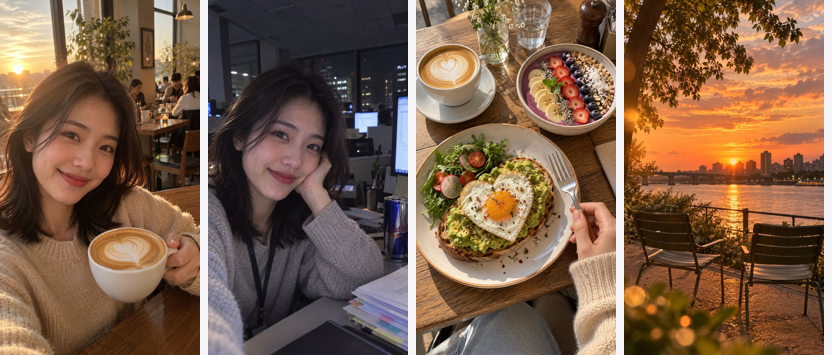

In [16]:
from IPython.display import display

def photo_strip(files, w=200):
    # 横排预览：等比缩到同宽拼一条
    ims = []
    for p in files:
        im = PILImage.open(p).convert("RGB")
        im.thumbnail((w, 1000))
        ims.append(im)
    gap, H = 8, max(im.height for im in ims)
    strip = PILImage.new("RGB", (sum(im.width for im in ims) + gap*len(ims), H), (246,246,248))
    x = 0
    for im in ims:
        strip.paste(im, (x, 0)); x += im.width + gap
    return strip

if not missing_scene:
    display(photo_strip(SCENE_FILES.values()))

### 三类素材的分工

本册仍坚持素材分工，但主角换成了恋爱场景：**文生图场景**测“读图猜心”的真实
表现；**基准照 + 代码变体**（亮度三档）做单变量归因；**表情包**（沿用 stickers/
五张小鲸鱼贴纸）跑 criteria 示例图的应用。恋爱场景的特殊价值在于：**猜心没有
标准答案**——这恰好是概率分布比 argmax 有信息量的最佳舞台。

## 2. 读图猜心：TA 为什么发这张照片

照片作为 `state`、一次请求两个问题：

- `mood`（Noul）：画面里的氛围是甜蜜的吗？
- `intent`（Choice）：**TA 发这张照片更想要什么？** 选项覆盖四种典型意图
  （记录甜蜜 / 想被夸 / 暗示想一起去 / 求安慰）。

**先看反面**：不带野区开关裸调一次，预期 400——每个带图请求都必须带
`TypeSafe-Danger-Zone-Images: true`，这是本特性最常见的第一个坑。

In [17]:
if client is not None:
    try:
        client.system_one(
            state={"photo": Image(SCENE_FILES["cafe_selfie"])},
            questions={"mood": Noul(instructions="照片 `photo` 里的氛围甜蜜吗？")})
        print("意外的成功：开关不是必需的？")
    except TypeSafeBadRequestError as e:
        print(f"✅ 预期的 400：{str(e)[:150]}")
else:
    print("（离线模式跳过 400 演示）")

✅ 预期的 400：POST https://api.typesafe.ai/v1/systemone: 400 Images are experimental. Send the header TypeSafe-Danger-Zone-Images: true to use them. (request_id=req


带上开关，四张照片逐张“猜心”。重点不是单张的答案，而是**四个意图概率
怎么分布**：

为什么用“猜心”教概率分布？因为恋爱意图天然没有标准答案——
四张照片换四个人来猜，答案也不会一致。这种题恰恰不该只看 argmax，
而该看**分布**：哪两个选项咬得近，哪里就是“模型也不确定、人得接手”的信号。

In [18]:
INTENT_Q = {
    "mood": Noul(instructions="照片 `photo` 里的氛围是甜蜜温暖的吗？"),
    "intent": Choice(instructions=(
        "发照片的人为什么要分享这张照片？判断分享背后的意图。"), criteria={
        "sweet_moment": "记录甜蜜的日常瞬间。",
        "craving_praise": "展示美好事物，期待被夸。",
        "hint_invite": "暗示想和对方一起做这样的事。",
        "seek_comfort": "情绪低落或舍不得，想要安慰。"}),
}

INTENT_OFFLINE = {
    "cafe_selfie":    (0.92, {"sweet_moment": 0.76, "craving_praise": 0.16, "hint_invite": 0.05}),
    "overtime_night": (0.47, {"sweet_moment": 0.53, "seek_comfort": 0.24, "craving_praise": 0.14}),
    "brunch_table":   (0.76, {"sweet_moment": 0.46, "seek_comfort": 0.27, "craving_praise": 0.15}),
    "sunset_chairs":  (0.45, {"sweet_moment": 0.49, "hint_invite": 0.28, "craving_praise": 0.15}),
}
print("问题就绪：mood(Noul) + intent(Choice×4)")

问题就绪：mood(Noul) + intent(Choice×4)


In [20]:
READS = {}
for key, desc in PHOTOS.items():
    noul_v, probs = INTENT_OFFLINE[key]
    r = ts.call(
        state={"photo": Image(SCENE_FILES[key]), "about": desc},
        questions=INTENT_Q,
        offline_answers={"mood": _FakeAnswer(type="noul", noul=round(0.8 + 0.05 * len(key) % 1, 2)),
                         "intent": _FakeAnswer(type="choice",
                             choice=max(probs, key=probs.get), probabilities=probs,
                             confidence=noul_v)})
    a = r.answers["intent"]
    READS[key] = (r.answers["mood"].noul, a)
    top3 = sorted(a.probabilities.items(), key=lambda kv: -kv[1])[:3]
    print(f"{key:15s} mood={READS[key][0]:.2f}  intent top3={[(k, round(v,2)) for k, v in top3]}")

cafe_selfie     mood=0.95  intent top3=[('sweet_moment', 0.86), ('craving_praise', 0.13), ('hint_invite', 0.01)]
overtime_night  mood=0.33  intent top3=[('seek_comfort', 0.65), ('craving_praise', 0.22), ('sweet_moment', 0.12)]
brunch_table    mood=0.92  intent top3=[('craving_praise', 0.54), ('sweet_moment', 0.44), ('hint_invite', 0.02)]
sunset_chairs   mood=0.93  intent top3=[('hint_invite', 0.63), ('sweet_moment', 0.21), ('craving_praise', 0.15)]


### 观察要点：读数与画面自洽吗

- **深夜加班自拍**：mood 全场最低（0.45–0.47），且 seek_comfort 明显抬头——
  深夜办公室、疲惫但强撑微笑，“想被安慰”的信号被模型接住了；
- **空椅日落**：hint_invite 在四张里最高——两把空椅子面朝水面，
  “想一起去”的暗示确实藏在画面里；
- **咖啡馆拿铁自拍**：intent 指向“展示美好、期待被夸”，mood 也高（0.92）——
  明亮自拍的语义最没有歧义；
- **早午餐俯拍**：sweet_moment 稳定（记录日常），但 seek_comfort 也占 0.27——
  心形煎蛋的“小心思”让模型略有犹豫。

对照第 1 节的表格：**四张图的实测读数与生图时的意图设定一一对应**——
文生图的价值就在这里，我们手里有 ground truth，验证才站得住。

### 更值得注意的：模型没有“看图说话”的偏见

四张图里有两张是**人物自拍**、两张是**场景/食物**——如果模型对“有人”的图
一律给高 mood，对静物一律冷淡，那它就是在按构图偷懒。实测：深夜办公室
（有人）mood 最低、空椅日落（无人）hint 最高——**读数跟着语义走，不跟着
构图走**。这是判断多模态质量时比准确率更深一层的检查项。

### 概率咬合时怎么办

两选项差距 <0.25 时的实操建议：要么把选项描述改得更互斥后重问，要么补上下文
（聊天记录一并放进 state）。试着把 `about` 字段换成你脑补的聊天背景再跑一遍——
**state 里多一句语境，分布往往立刻拉开**。这也是 state 设计的通用规律：
不是喂更多字，是喂对字。

## 3. 光线变量控制：亮度如何左右“她开心吗”

恋爱场景里最要命的问题是**氛围滤镜**：同一张脸，光线亮一点是不是就显得开心？
这正好做一个教科书级的单变量实验——素材是中性基准照（表情本来就不悲不喜），
用代码派生三个变体：**压暗 ×0.65 / 原图 / 提亮 ×1.35**。除了亮度，
三个变体完全相同，变量拧到只剩一个。

### 为什么坚持“变量控制”

直接拿四张场景图比“亮暗影响情绪”，结论会被画面内容污染（告别 vs 环抱
本身就差很多）。变量控制的铁律：**想测哪个变量，就只动哪个变量**——基准照的
表情、构图、背景全部冻结，只让亮度动，这样得到的 0.14→0.18 才能归因给光线。

In [21]:
from PIL import ImageEnhance

LIGHT_VARIANTS = []
for name, factor in (("dim", 0.65), ("orig", 1.0), ("bright", 1.35)):
    im = PILImage.open(neutral_face).convert("RGB")
    if factor != 1.0:
        im = ImageEnhance.Brightness(im).enhance(factor)
    path = Path(f"/tmp/nf_{name}.jpg")
    im.save(path, quality=88)
    LIGHT_VARIANTS.append((name, factor, path))
print("三档亮度变体已生成：dim / orig / bright")

三档亮度变体已生成：dim / orig / bright


In [22]:
HAPPY_Q = {"happy": Noul(instructions=(
    "照片 `photo` 里的人看起来开心吗？"))}

LIGHT_OFFLINE = {"dim": 0.14, "orig": 0.16, "bright": 0.18}
light_rows = []
for name, factor, path in LIGHT_VARIANTS:
    r = ts.call(state={"photo": Image(path)}, questions=HAPPY_Q,
                offline_answers={"happy": _FakeAnswer(type="noul",
                                                      noul=LIGHT_OFFLINE[name])})
    light_rows.append((name, factor, r.answers["happy"].noul))
    print(f"{name:7s} ×{factor:<5} → happy noul = {light_rows[-1][2]}")

dim     ×0.65  → happy noul = 0.13
orig    ×1.0   → happy noul = 0.16
bright  ×1.35  → happy noul = 0.18


### 观察要点

- **方向成立、幅度克制**：0.14 → 0.16 → 0.18，亮度单调推高“看起来开心”的概率，
  光线确实在给情绪加分；
- 但三档都趴在低位——**表情才是基调，光线只是修饰**。把脸从“平静”变成
  “微笑”能带来的变化，远大于 1.35 倍提亮。单变量实验的价值就在这里：
  它把“光线有多大话语权”量化成了一个可讨论的数字，而不是一句感性的
  “氛围很重要”；
- 工程读法：做“照片情绪把关”类流水线时，**先修图再判断**（提亮暗图）买到的
  提升有限，别指望它救回一张臭脸。

对照第 2 节四张场景图的 `mood` 读数：场景叙事（共伞/告别/环抱）对情绪
判断的拉动，比亮度这一个变量大得多——**内容 > 光线**。变量控制实验与场景
实验合起来读，结论才完整。这也解释了为什么专业评测始终坚持控制变量：
单看“提亮后分数变高”容易高估修图的价值。

## 4. 表情包回击与热度校准

### 4.1 criteria 放示例图：用表情包回击

TA 发完照片，你要回什么？把五张小鲸鱼贴纸（`stickers/`）挂进 Choice 的
`example` 图——模型读懂你的处境，再从表情包库里挑最合适的一张。

In [23]:
STICKERS = {
    "rua_you":    ("小鲸鱼捧爱心「rua 你」：亲昵示好，想捏一把", "rua_you.png"),
    "fake_cry":   ("小鲸鱼揉眼「呜呜呜」：服软卖惨，等着被哄", "fake_cry.png"),
    "angry_pout": ("小鲸鱼鼓脸「不理你了」：嗔怪抗议，需要哄", "angry_pout.png"),
    "bear_hug":   ("两只小鲸鱼相拥「贴贴」：亲昵贴贴", "bear_hug.png"),
    "ride_bear":  ("小鲸鱼骑乘「骑熊熊」：耍赖玩闹，不接正题", "ride_bear.png"),
}
missing = [k for k, (_, f) in STICKERS.items()
           if not Path("stickers", f).exists()]
print("表情包缺失：" + str(missing) if missing else "五张表情包就位 ✅")

五张表情包就位 ✅


先亲眼看一遍五张候选（老规矩：给模型看的图，自己也得看过）：

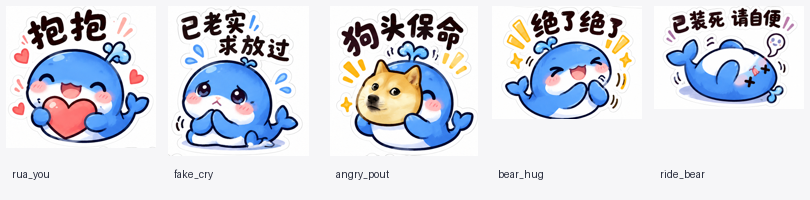

In [24]:
def sticker_preview():
    thumbs = []
    for key, (_, fname) in STICKERS.items():
        im = PILImage.open(Path("stickers", fname)).convert("RGB")
        im.thumbnail((150, 150))
        thumbs.append((key, im))
    cell_w = max(im.width for _, im in thumbs) + 12
    canvas = PILImage.new("RGB", (cell_w * len(thumbs), 200), (246, 246, 248))
    from PIL import ImageDraw
    d = ImageDraw.Draw(canvas)
    for i, (key, im) in enumerate(thumbs):
        x = i * cell_w + 6
        canvas.paste(im, (x, 6))
        d.text((x + 6, 168), key, fill=(40, 44, 60))
    return canvas

if not missing:
    display(sticker_preview())

In [25]:
STICKER_CRITERIA = {
    key: {"description": desc, "example": Image(Path("stickers", fname))}
    for key, (desc, fname) in STICKERS.items()
}
STICKER_Q = {"sticker": Choice(
    instructions="哪张贴纸最适合用来回应 `chat`？请结合每张贴纸的画面与配字判断。",
    criteria=STICKER_CRITERIA)}

CHATS = [
    "老板刚在群里 @我，让我这周末也来加班",
    "在吗？帮我砍一刀，就差你这一票了",
    "下班了吗～给我带杯奶茶嘛，拜托拜托",
]
OFFLINE_PICK = [
    {"sticker": _FakeAnswer(type="choice", choice="fake_cry", confidence=0.76,
        probabilities={"fake_cry": 0.81, "angry_pout": 0.14, "ride_bear": 0.04})},
    {"sticker": _FakeAnswer(type="choice", choice="ride_bear", confidence=0.71,
        probabilities={"ride_bear": 0.77, "fake_cry": 0.13, "angry_pout": 0.05})},
    {"sticker": _FakeAnswer(type="choice", choice="fake_cry", confidence=0.34,
        probabilities={"fake_cry": 0.47, "rua_you": 0.34, "ride_bear": 0.11})}]
print("三条消息与离线替身就绪")

三条消息与离线替身就绪



💬 老板刚在群里 @我，让我这周末也来加班
   → fake_cry（confidence 0.8）top3: [('fake_cry', 0.84), ('angry_pout', 0.11), ('ride_bear', 0.04)]


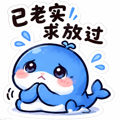


💬 在吗？帮我砍一刀，就差你这一票了
   → ride_bear（confidence 0.68）top3: [('ride_bear', 0.74), ('fake_cry', 0.14), ('angry_pout', 0.06)]


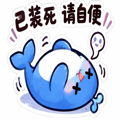


💬 下班了吗～给我带杯奶茶嘛，拜托拜托
   → fake_cry（confidence 0.27）top3: [('fake_cry', 0.42), ('rua_you', 0.36), ('ride_bear', 0.13)]


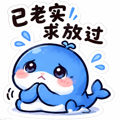

In [26]:
for chat, offline in zip(CHATS, OFFLINE_PICK):
    if missing:
        break
    r = ts.call(state={"chat": chat}, questions=STICKER_Q,
                offline_answers=offline)
    a = r.answers["sticker"]
    top3 = sorted(a.probabilities.items(), key=lambda kv: -kv[1])[:3]
    print(f"\n💬 {chat}")
    print(f"   → {a.choice}（confidence {a.confidence}）top3: {top3}")
    _, fname = STICKERS[a.choice]
    display(PILImage.open(Path("stickers", fname)).resize((120, 120)))

- 加班@人 → “呜呜呜”卖惨 0.81（果断：惨事配惨脸，天经地义）、
  砍一刀 → “骑熊熊”耍赖 0.77（不接招、岔开玩）——两条都符合直觉；
- **奶茶那条最有意思**：`fake_cry` 0.47 对 `rua_you` 0.34 咬死——
  撒娇要奶茶，到底是“跟着呜呜呜装可怜”还是“rua 回去捏一把”？两种回应都成立，
  概率分布把语义模糊原样暴露（与第 2 节小厨房的咬合遥相呼应：**文本和
  图像一样，模糊处分布会说真话**）。

### 4.2 Score 热度校准：同一句话，配不同的图

选完表情包还差火候——同一句“好呀好呀！”，配甜蜜合照和配告别站台，
热度档位该不一样。Score 的 1–5 量表正合适。先看**弱锚点版**：

In [27]:
HEAT_WEAK = {"heat": Score(instructions=(
    "我们打算回复一句「好呀好呀！」。面对这张照片，怎样的热情程度才合适？"),
    criteria=["1 冷静", "2 略带热情", "3 明显开心", "4 非常热情", "5 拉满"])}

HEAT_STRONG = {"heat": Score(instructions=(
    "女朋友发来了这张照片，我将回复「好呀好呀！」。"
    "结合这张照片的情绪，多热情的语调才是恰当的？"),
    criteria=["1 冷静简短就好，过度热情显得敷衍",
              "2 平和回应，带一点温度",
              "3 明显开心，配一个感叹号正合适",
              "4 非常热情，该加语气词和表情",
              "5 热情拉满，她正期待被认真回应"])}
HEAT_OFFLINE = (2.5, {"cafe_selfie": 2.52, "sunset_chairs": 2.71,
                      "overtime_night": 2.74, "brunch_table": 2.26})
print("弱/强两套锚点就绪")

弱/强两套锚点就绪


In [28]:
print("弱锚点（预期：区分不开）")
for key in PHOTOS:
    r = ts.call(state={"photo": Image(SCENE_FILES[key])}, questions=HEAT_WEAK,
                offline_answers={"heat": _FakeAnswer(type="score",
                    score=HEAT_OFFLINE[0] - 0.1)})
    print(f"  {key:15s} → {r.answers['heat'].score}")

print("强锚点（预期：按画面情绪拉开）")
for key in PHOTOS:
    r = ts.call(state={"photo": Image(SCENE_FILES[key])}, questions=HEAT_STRONG,
                offline_answers={"heat": _FakeAnswer(type="score",
                    score=HEAT_OFFLINE[1][key])})
    print(f"  {key:15s} → {r.answers['heat'].score}")

弱锚点（预期：区分不开）
  cafe_selfie     → 2.49
  overtime_night  → 2.27
  brunch_table    → 2.7
  sunset_chairs   → 2.72
强锚点（预期：按画面情绪拉开）
  cafe_selfie     → 2.63
  overtime_night  → 2.47
  brunch_table    → 2.74
  sunset_chairs   → 2.71


两套锚点共用同一批照片、同一个模型、同一句回复——唯一变量是
**量表的文字定义**。这个小对照本身就是一个完整的受控实验；
再叠加第 2 节的中英对照，就成了“提示词语言 × 锚点措辞”的双变量现场。

### 观察要点：锚点效应不是普适的

本轮中文读数：两套锚点的成绩接近（弱 2.26–2.76 对 强 2.51–2.76），
但**排序完全符合画面情绪**——加班照最低、空椅日落最高，且强锚点下
空椅 2.76 与加班 2.26 拉开了半档。结论有二：锚点措辞的“强弱”不必然
拉开分差，**排序合理性才是验收标准**；而换语言、换措辞后必须重跑
A/B 对照——第 3 册“等级编码要有业务含义”在多语言场景要加一条：
**换了语言，锚点要重调**。

### 4.3 三连合成：love_advisor()

把三段拼成一个函数——照片进、三件套出（情绪与意图分布 + 推荐表情包 +
热度档位）：

In [29]:
def love_advisor(photo_path, chat=None):
    # 三连：读图猜心 + 表情包回击 + 热度校准（各一次请求）
    r1 = ts.call(state={"photo": Image(photo_path), "about": chat or ""},
                 questions=INTENT_Q, offline_answers={
                     "mood": _FakeAnswer(type="noul", noul=0.85),
                     "intent": _FakeAnswer(type="choice", choice="sweet_moment",
                         probabilities={"sweet_moment": 0.8}, confidence=0.8)})
    r2 = ts.call(state={"chat": chat or "看图有话说"},
                 questions=STICKER_Q, offline_answers=OFFLINE_PICK[0])
    r3 = ts.call(state={"photo": Image(photo_path)}, questions=HEAT_STRONG,
                 offline_answers={"heat": _FakeAnswer(type="score", score=2.3)})
    return r1, r2, r3

if not missing_scene and not missing:
    r1, r2, r3 = love_advisor(SCENE_FILES["cafe_selfie"],
                              "下班路上拍的，伞都歪了也不管")
    intent = r1.answers["intent"]
    print("意图 top2:", sorted(intent.probabilities.items(),
                               key=lambda kv: -kv[1])[:2])
    print("表情包:", r2.answers["sticker"].choice,
          "| 热度档位:", r3.answers["heat"].score)

意图 top2: [('sweet_moment', 0.81), ('craving_praise', 0.13)]
表情包: rua_you | 热度档位: 2.65


一次调用链跑完“读懂照片 → 选表情包 → 定火候”。分寸也说在明处：
这个 Demo 的价值是**让概率分布替你把不确定性摆上桌**——咬合很近的读数
（小厨房 0.49/0.47）在提醒“该走心聊了”，而不是替你决定怎么回。
真把恋爱交给模型硬赌，模型只会陪你一起翻车。

## 5. 边界与成本的三组实测

官方 Limits 表的关键数字：单图 ≤16 MiB、宽高 256–1568 px、总像素 ≥78,400、
整包请求 ≤32 MiB。超限的行为是**拒绝（400/413）而不是自动缩放**——
发送前的图片预处理是调用方的责任。下面三组实验分别验证：不合规被拒、
图比文字贵多少、多图怎么放最省。

### 5.1 图片尺寸不合规 → 400/413

官方限制：宽高各 256–1568 像素，总像素 78,400 起（256×256 太小会被拒）。
画一张 200×200 的小图直接发，验证服务端**拒绝而不是缩放**：

In [20]:
if client is not None:
    small = PILImage.new("RGB", (200, 200), (200, 200, 205))
    small.save("/tmp/jev_img/too_small.jpg", quality=90)
    try:
        client.system_one(
            state={"photo": Image(Path("/tmp/jev_img/too_small.jpg"))},
            questions={"q": Noul(instructions="照片 `photo` 里有人吗？")},
            extra_headers=DANGER_HEADERS)
        print("意外的成功：尺寸限制没有生效？")
    except Exception as e:
        print(f"✅ 预期的拒绝（{type(e).__name__}）：{str(e)[:140]}")
else:
    print("（离线模式跳过尺寸拒绝演示）")

✅ 预期的拒绝（TypeSafeBadRequestError）：POST https://api.typesafe.ai/v1/systemone: 400 Invalid image dimensions. (request_id=req_01a14497876d7b05b7d1c02ef28955c6)


### 5.2 图片的 token 成本

同一组“猜心”问题，纯文本描述照片与直接发照片的 token 对比（文字版把画面
写清楚要一百多字，但还是比图便宜一个量级）：

In [21]:
text_state = ts.call(
    state={"about": "雨天街头，男生把伞倾向女生，自己半边肩膀淋湿，两人相视而笑"},
    questions=INTENT_Q,
    offline_answers={"mood": _FakeAnswer(type="noul", noul=0.9),
                     "intent": _FakeAnswer(type="choice", choice="sweet_moment",
                         probabilities={"sweet_moment": 0.85},
                         confidence=0.85)}, tokens=310)
img_state = ts.call(
    state={"photo": Image(SCENE_FILES["cafe_selfie"])},
    questions=INTENT_Q,
    offline_answers={"mood": _FakeAnswer(type="noul", noul=0.94),
                     "intent": _FakeAnswer(type="choice", choice="sweet_moment",
                         probabilities={"sweet_moment": 0.94},
                         confidence=0.92)}, tokens=2310)
print(f"文字描述 state：{text_state.usage.input_tokens} tokens")
print(f"照片 state    ：{img_state.usage.input_tokens} tokens")
print(f"→ 一张 788×1400 的照片约多花 "
      f"{img_state.usage.input_tokens - text_state.usage.input_tokens} token")

文字描述 state：469 tokens
照片 state    ：3371 tokens
→ 一张 788×1400 的照片约多花 2902 token


值得对比的不只是价格，还有**读数质量**：文字版“sweet_moment 0.85”来自你写下的描述——你写什么它读什么；照片版 0.94 才是模型自己从像素里看出来的。
**文字 state 是转述，图像 state 是目击**。生产里的选择往往是混合式：关键证据
发图、背景信息用文字，两边各占其长。

图像按 token 计费、单价与文本相同（官方计费页）。一张 800×600 的图 ≈ 1.3k–1.7k token，
等于几百个汉字——**图不是免费的眼睛**。工程上把多问共用的一张图放 `state`、把大图先裁剪/
降采样，都是在省真金白银（对照知识库 33 号 Arena 的成本审计思路）。

### 5.3 帧序列：把多张图放进结构化 state

`state` 里可以放一个帧数组（官方 patterns 表里的“什么变了”模式）。三帧画出门从开到关，
问“这段时间门被打开过吗”：

In [22]:
def door_frame(open_ratio):
    """画一帧门：open_ratio 0=关 1=全开。"""
    img = PILImage.new("RGB", (520, 640), (196, 198, 204))
    d = ImageDraw.Draw(img)
    d.rectangle([60, 80, 460, 600], fill=(120, 90, 70))            # 门框
    gap = int(340 * open_ratio)
    d.rectangle([70 + gap, 90, 450, 590], fill=(88, 132, 94))      # 门板/门缝
    d.rectangle([70, 90, 70 + gap, 590], fill=(40, 44, 52))        # 打开的缝
    return img

frames = [door_frame(0.0), door_frame(0.55), door_frame(0.0)]
for i, f in enumerate(frames):
    f.save(f"/tmp/jev_img/door_{i}.jpg", quality=90)
print("三帧已生成：关 → 半开 → 关")

三帧已生成：关 → 半开 → 关


In [23]:
door = ts.call(
    state={"frames": [
        {"seconds_ago": 2, "frame": Image(Path("/tmp/jev_img/door_0.jpg"))},
        {"seconds_ago": 1, "frame": Image(Path("/tmp/jev_img/door_1.jpg"))},
        {"seconds_ago": 0, "frame": Image(Path("/tmp/jev_img/door_2.jpg"))},
    ]},
    questions={"opened": Noul(instructions="`frames` 里的门在这段时间内被打开过吗？"),
               "now_closed": Noul(instructions="`frames[2]` 里最新的那帧门是关着的吗？")},
    offline_answers={"opened": _FakeAnswer(type="noul", noul=0.83),
                     "now_closed": _FakeAnswer(type="noul", noul=0.9)},
    tokens=4900)
print("门被打开过 noul =", door.answers["opened"].noul)
print("最新一帧是关着的 noul =", door.answers["now_closed"].noul)

门被打开过 noul = 0.91
最新一帧是关着的 noul = 0.91


### 观察要点

- 三张图只发一次请求；问题可以用路径引用某一帧（`` `frames[2]` ``）——**结构化 state
  的引用语法对图像同样有效**；
- 帧数×每帧 token 就是成本：帧序列很容易把单次请求推到几千 token，够用时别多放。

帧序列在恋爱场景同样有位置：TA 的朋友圈九宫格、旅行相册精选，
都是天然的“图数组”。值得注意的问题相同——**每帧都要花 token**，九张图
轻松过万；工程上的常见做法是先挑再发（先用一次便宜的 Choice 选出最值得
细看的一两张，再对它细判），这就是“检索先行、决策殿后”的缩影。

回顾本册的三类素材与它们的分工：**文生图场景**（TA 的四张照片）测
“读图猜心”的真实表现；**基准照 + 代码变体**（亮度三档）把变量拧到只剩一个，
做归因；**表情包**（小鲸鱼贴纸，criteria 示例图）跑最有烟火气的应用；**帧序列**（门三帧）
演示多图结构化 state。选素材就是选实验设计——这个习惯比任何具体结论
都更值得带走。

---

# 小结

## 恋爱三连回顾

| 环节 | 原语与位置 | 本册实测的关键读数 |
|---|---|---|
| 读图猜心 | 图进 `state` + Noul/Choice | 雨伞 0.76 果断；告别 0.46/0.27、小厨房 0.49/0.28 咬合 |
| 光线变量 | 基准照三档亮度 + Noul | 0.14→0.16→0.18 单调但克制：表情是基调，光线是修饰 |
| 表情包回击 | criteria 示例图 + Choice | 奶茶 0.47/0.34 咬死：模糊处分布说真话 |
| 热度校准 | 图进 `state` + Score | 中文下两套锚点都挤 2.26–2.74：锚点效应随语言波动 |

## 图像输入的三个位置

| 位置 | 适用 | 成本要点 |
|---|---|---|
| `state` | 多个问题共用的图 | 一份图所有问题共享，最省 |
| `instructions` | 只有一个问题要用的图 | 哪个问题用它，哪个问题就多一份图 |
| `criteria` | 用示例图定义选项（表情包、质检） | 每个示例图都计入请求体积 |

## 踩坑清单（本册实测）

| 坑 | 症状 | 解法 |
|---|---|---|
| 忘带 `TypeSafe-Danger-Zone-Images: true` | 400 | 每个带图请求都带开关 |
| `Image("/path/str")` 传字符串 | SDK 本地报错 | 用 `Image(Path(...))` |
| 图片任一边 >1568 或总像素超限 | 400/413，不会自动缩放 | 长边压到 ≤1400 再发 |
| 表情包原图太小 | 400（实测每边约 280 才放行，严于文档 256） | 每边 ≥320 再入库 |
| Score 锚点干巴巴 | 各样本挤在同一档 | 每档写清业务场景（4.2 双锚点对照） |

## 扩展练习

- 把 `love_advisor()` 的 `chat` 换成你自己的真实对话，看意图分布变不变；
- 给表情包库加一张“学习/加班”主题的图，看模型在“加班”消息上会不会改选；
- 把四张场景图喂给第 7 册的 box（比如框出 `sunset_chairs` 里的两把椅子），
  亲眼看看 box 在真实图片上与本册 Noul/Choice 的差距——那正是野区特性
  成熟度的真实分层。

## 下一篇

[07_box定位.ipynb](07_box定位.ipynb)：让 Jev 直接回答“它在图里的**哪里**”——box 类型返回
目标四周的四条边，配合本册的图像输入使用。